# Chapitre 1 — Qubit, sphère de Bloch et Mach-Zehnder

Un état de qubit s'écrit $\cos(\theta/2)|0\rangle + e^{i\varphi}\sin(\theta/2)|1\rangle$. On le place sur la sphère de Bloch, puis on retrouve numériquement $P(x)=\cos^2(\varphi/2)$ de l'exercice 1.9.

*Carnet PHY321 — fonctionne sans connexion : numpy et matplotlib suffisent.*

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(321)  # graine fixe : résultats reproductibles

In [2]:
theta, phi = 1.0, 0.5
psi = np.array([np.cos(theta/2), np.exp(1j*phi)*np.sin(theta/2)])
sx = np.array([[0,1],[1,0]]); sy = np.array([[0,-1j],[1j,0]]); sz = np.array([[1,0],[0,-1]])
bloch = np.array([np.real(psi.conj() @ s @ psi) for s in (sx, sy, sz)])
print("vecteur de Bloch", bloch, "norme", np.linalg.norm(bloch))
print("P(0) =", abs(psi[0])**2, "  cos^2(theta/2) =", np.cos(theta/2)**2)

vecteur de Bloch [0.7385 0.4034 0.5403] norme 1.0
P(0) = 0.7701511529340699   cos^2(theta/2) = 0.7701511529340699


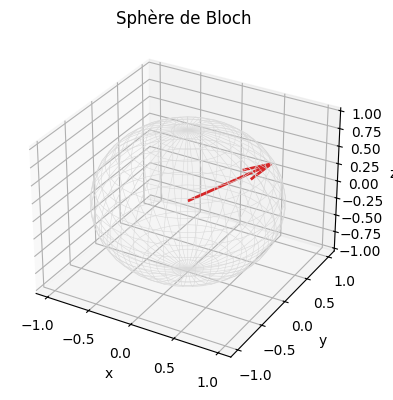

In [3]:
fig = plt.figure(figsize=(4.5, 4.5)); ax = fig.add_subplot(projection='3d')
u, v = np.mgrid[0:2*np.pi:40j, 0:np.pi:20j]
ax.plot_wireframe(np.cos(u)*np.sin(v), np.sin(u)*np.sin(v), np.cos(v), color='0.85', linewidth=0.4)
ax.quiver(0, 0, 0, *bloch, color='C3', linewidth=2)
ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('z'); ax.set_title("Sphère de Bloch")
plt.show()

## Interféromètre de Mach-Zehnder

Séparatrice $B$, paire de miroirs $M$, lame de phase $\Phi$ (exercice 1.9).

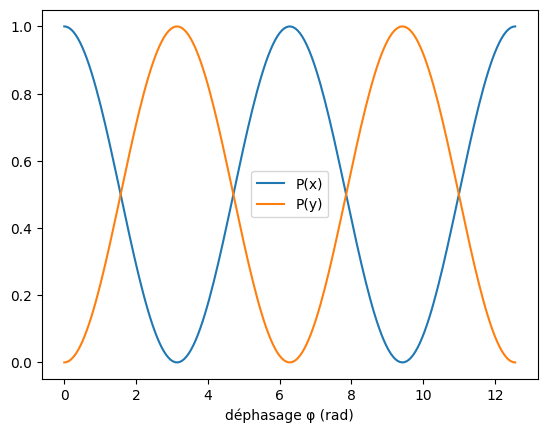

P(x) = cos²(φ/2) vérifié sur 200 valeurs de φ


In [4]:
B = np.array([[1, 1j], [1j, 1]]) / np.sqrt(2)
M = np.array([[0, 1j], [1j, 0]])
phis = np.linspace(0, 4*np.pi, 200)
Px = []
for ph in phis:
    Phi = np.diag([np.exp(1j*ph), 1])
    out = B @ M @ Phi @ B @ np.array([1, 0])
    Px.append(abs(out[0])**2)
Px = np.array(Px)
assert np.allclose(Px, np.cos(phis/2)**2)
plt.plot(phis, Px, label='P(x)'); plt.plot(phis, 1-Px, label='P(y)')
plt.xlabel("déphasage φ (rad)"); plt.legend(); plt.show()
print("P(x) = cos²(φ/2) vérifié sur 200 valeurs de φ")